# Which machine took this eye scan?
### A hands-on introduction to machine learning with synthetic AI-READI data

In this notebook you will teach a computer to recognize which machine took a picture of the back of the eye, even
from small, plain pieces of the picture that people cannot tell apart. Along the way you will see how machine
learning works from first principles: what a model is, how it measures its own mistakes, how it learns from them,
and why one kind of model, the convolutional neural network, is the right tool for pictures.

You do not need to know how to program. Run each gray code box in order with **Shift + Enter** and read the text
around it.

**Plan**

1. Check your computer
2. Meet the data
3. Machine learning from first principles
4. From numbers to pictures: why a convolutional neural network
5. The challenge: which machine took this scan?
6. What it means
7. Data license and credits

## 1. Check your computer

Everything runs on an ordinary laptop. No graphics card, cloud account or internet connection is needed once the
software is installed.

| | Needed | Comfortable |
|---|---|---|
| Processor | 2 cores | 4 or more cores |
| Memory | 4 GB | 8 GB |
| Free disk space | 2 GB (software about 1.5 GB, data 75 MB) | |
| Software | Python 3.10 or newer, with the packages in `requirements.txt` | |
| Time to run every cell | about 5 minutes on 4 cores | |

The next two cells check the software and report what your computer has.

In [1]:
import importlib.util
needed = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib", "seaborn": "seaborn",
          "sklearn": "scikit-learn", "torch": "torch", "PIL": "pillow"}
missing = [pkg for module, pkg in needed.items() if importlib.util.find_spec(module) is None]
print("all packages present" if not missing else
      f"missing: {', '.join(missing)}. In a terminal, run: pip install -r requirements.txt")

all packages present


In [2]:
import os, platform, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

DATA = Path("data")
SEED = 42
cores = len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else os.cpu_count()
torch.set_num_threads(min(4, cores))          # leave room for the rest of the computer
try:
    memory_gb = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1e9
except (ValueError, AttributeError, OSError):
    memory_gb = float("nan")                  # not reported on Windows

# one chart style for the whole notebook
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SLOTS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
BLUES = sns.blend_palette(["#f0efec", "#86b6ef", "#2a78d6", "#0d366b"], as_cmap=True)
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": AXIS, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 11, "font.size": 10, "lines.linewidth": 2, "figure.dpi": 110,
})

def no_axes(ax):
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for side in ax.spines.values():
        side.set_visible(False)

print(f"Python {platform.python_version()} on {platform.system()}")
print(f"processor cores: {cores} (training will use {torch.get_num_threads()})")
print("memory: " + ("not reported on this system" if memory_gb != memory_gb else
                    "enough (4 GB needed)" if memory_gb >= 4 else "below the 4 GB needed"))
print(f"graphics card: {'present, not needed' if torch.cuda.is_available() else 'none, not needed'}")
print(f"data folder: {len(list((DATA / 'scans').glob('*.png'))):,} scans found" if DATA.exists()
      else "data folder not found: put the 'data' folder next to this notebook")

Python 3.12.3 on Linux
processor cores: 4 (training will use 4)
memory: enough (4 GB needed)
graphics card: none, not needed
data folder: 2,000 scans found


## 2. Meet the data

AI-READI is a large study of type 2 diabetes that collects eye pictures, heart tracings, blood tests, glucose
monitors and activity trackers from the same people. The real data requires a data agreement, so this workshop
uses a **synthetic** version made by the ADVANCE Center at Vanderbilt University Medical Center: a computer program
learned the patterns in the real data and generated new, made-up records that follow the same patterns. No record
belongs to a real person.

The `data` folder holds a small sample of it:

| | |
|---|---|
| `scans/` | 2,000 retina cross-section scans, 500 from each of four machines |
| `gallery/` | 13 example pictures, one for each kind of picture and machine |
| `participants.csv` | 16 measurements for 10,518 synthetic participants |

### 2.1 Pictures of the eye

The study photographs the back of the eye, the **retina**, with several machines. Some take ordinary color photos,
some use infrared light. One kind, **optical coherence tomography (OCT)**, works like an ultrasound that uses light
instead of sound: it produces a cross-section through the layers of the retina. In this notebook we simply call
these **scans**.

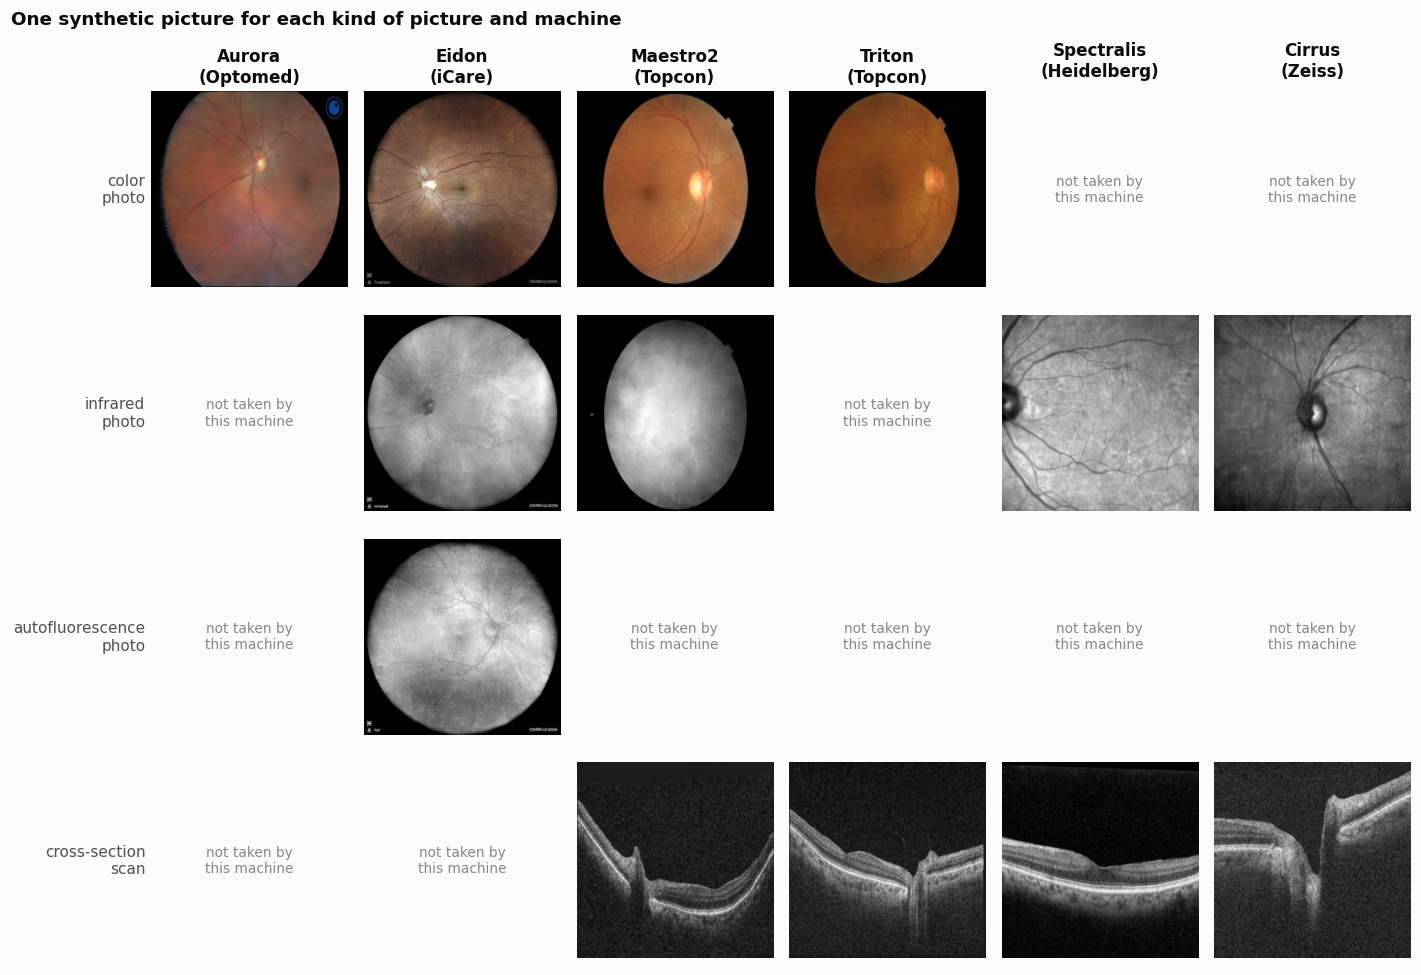

In [3]:
gallery = pd.read_csv(DATA / "gallery.csv")
KINDS = ["color photo", "infrared photo", "autofluorescence photo", "cross-section scan"]
MACHINE_ORDER = ["Aurora", "Eidon", "Maestro2", "Triton", "Spectralis", "Cirrus"]

fig, axes = plt.subplots(len(KINDS), len(MACHINE_ORDER), figsize=(13, 9))
for i, kind in enumerate(KINDS):
    for j, machine in enumerate(MACHINE_ORDER):
        ax = axes[i, j]
        no_axes(ax)
        row = gallery[(gallery.kind == kind) & (gallery.machine == machine)]
        if row.empty:
            ax.text(0.5, 0.5, "not taken by\nthis machine", ha="center", va="center", color=MUTED, fontsize=9)
        else:
            picture = np.array(Image.open(DATA / "gallery" / row.file.iloc[0]))
            if kind != "color photo" and picture.ndim == 3:
                picture = picture.mean(axis=2)
            ax.imshow(picture, cmap=None if picture.ndim == 3 else "gray")
        if i == 0:
            ax.set_title(f"{machine}\n({row.maker.iloc[0] if not row.empty else gallery[gallery.machine == machine].maker.iloc[0]})")
        if j == 0:
            ax.set_ylabel(kind.replace(" ", "\n", 1), rotation=0, ha="right", va="center", color=INK2)
fig.suptitle("One synthetic picture for each kind of picture and machine", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()

In [4]:
scans = pd.read_csv(DATA / "scans.csv")
MACHINES = sorted(scans.machine.unique())
pd.crosstab(scans.machine + " (" + scans.maker + ")", scans.area, margins=True, margins_name="total")

area,macula,optic disc,wide field,total
row_0,,,,
Cirrus (Zeiss),232,268,0,500
Maestro2 (Topcon),330,0,170,500
Spectralis (Heidelberg),297,203,0,500
Triton (Topcon),344,156,0,500
total,1203,627,170,2000


### 2.2 Measurements from many devices

Each row of `participants.csv` is one synthetic person. The columns come from different sources: blood tests,
a clinic visit, a 10-second clinic heart tracing, a continuous glucose monitor worn for days, and a wrist-worn
activity tracker (the "watch"). One blood test appears often below: **HbA1c**, which reflects average blood sugar
over the past three months or so; 6.5% or higher is the usual threshold for diabetes.

In [5]:
participants = pd.read_csv(DATA / "participants.csv", index_col="participant_id")
print(f"{len(participants):,} synthetic participants, {participants.shape[1]} measurements each")
participants.head()

10,518 synthetic participants, 16 measurements each


,type2_diabetes,high_blood_pressure,kidney_problems,hba1c_percent,lab_glucose_mg_dl,creatinine_mg_dl,body_mass_index,waist_cm,systolic_blood_pressure_mmhg,glucose_monitor_mean_mg_dl,glucose_monitor_variability_mg_dl,watch_heart_rate_bpm,watch_resting_heart_rate_bpm,watch_steps,watch_stress_score,clinic_heart_rate_bpm
participant_id,,,,,,,,,,,,,,,,
0,0,0,0,4.29,127.54,0.75,18.41,87.67,117.99,103.89,54.27,54.39,52.86,483.44,15.73,47.97
1,0,1,0,6.52,63.55,0.43,38.51,122.91,142.39,166.31,11.78,74.93,79.89,1081.65,71.43,70.11
2,1,1,0,5.81,59.29,0.53,33.70,120.18,119.89,141.81,81.48,75.92,77.86,472.48,65.59,62.24
3,1,1,0,8.35,110.16,1.07,49.91,114.68,109.62,173.59,23.04,87.31,86.93,702.24,67.88,69.57
4,0,1,0,4.62,49.55,0.35,29.16,121.29,106.46,135.20,6.01,82.42,85.50,437.66,82.07,56.48


### 2.3 Do the measurements hang together?

A **correlation** is a number between -1 and 1 that says how closely two measurements move together. Near 1: when
one is high, the other tends to be high. Near 0: no relationship. Near -1: when one is high, the other tends to be
low. If the synthetic data learned the real patterns, relationships we already know from medicine should show up.

In [6]:
checks = [  # (measurement A, measurement B, what medicine leads us to expect)
    ("clinic_heart_rate_bpm", "watch_heart_rate_bpm", "move together"),
    ("hba1c_percent", "glucose_monitor_mean_mg_dl", "move together"),
    ("hba1c_percent", "type2_diabetes", "move together"),
    ("body_mass_index", "waist_cm", "move together"),
    ("systolic_blood_pressure_mmhg", "high_blood_pressure", "move together"),
    ("creatinine_mg_dl", "kidney_problems", "move together"),
    ("watch_steps", "body_mass_index", "move in opposite directions"),
]
rows = []
for a, b, expected in checks:
    r = participants[a].corr(participants[b])
    kept = abs(r) >= 0.2 and (r > 0) == (expected == "move together")
    rows.append({"measurement A": a, "measurement B": b, "expected": expected,
                 "correlation": round(r, 2), "in this synthetic data": "kept" if kept else "much weaker than expected"})
pd.DataFrame(rows)

,measurement A,measurement B,expected,correlation,in this synthetic data
0,clinic_heart_rate_bpm,watch_heart_rate_bpm,move together,0.69,kept
1,hba1c_percent,glucose_monitor_mean_mg_dl,move together,0.26,kept
2,hba1c_percent,type2_diabetes,move together,0.33,kept
3,body_mass_index,waist_cm,move together,0.49,kept
4,systolic_blood_pressure_mmhg,high_blood_pressure,move together,0.05,much weaker than expected
5,creatinine_mg_dl,kidney_problems,move together,0.03,much weaker than expected
6,watch_steps,body_mass_index,move in opposite directions,0.00,much weaker than expected


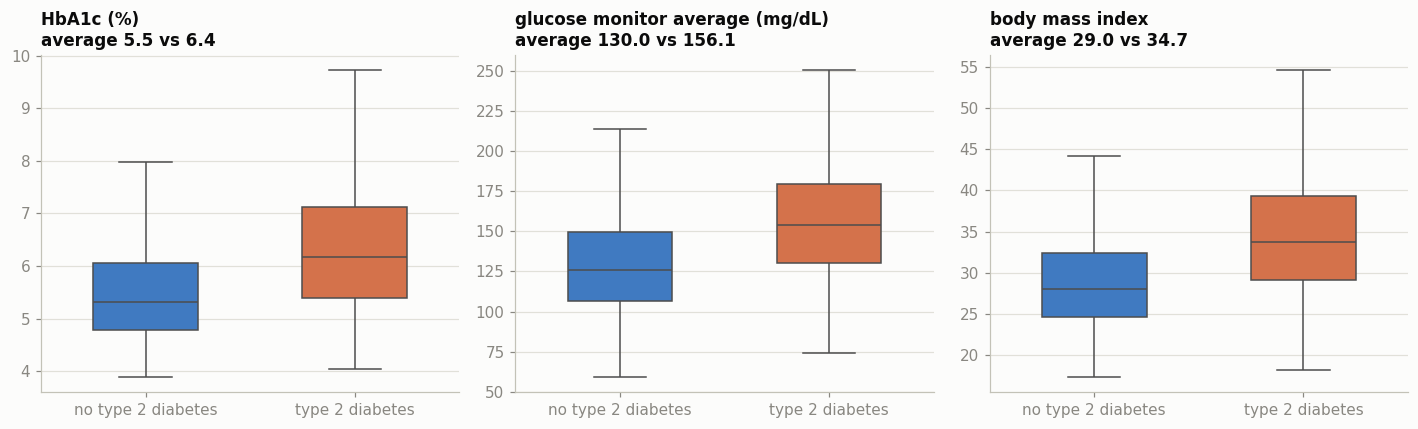

In [7]:
groups = participants.assign(group=participants.type2_diabetes.map({0: "no type 2 diabetes", 1: "type 2 diabetes"}))
panels = [("hba1c_percent", "HbA1c (%)"), ("glucose_monitor_mean_mg_dl", "glucose monitor average (mg/dL)"),
          ("body_mass_index", "body mass index")]
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (column, label) in zip(axes, panels):
    sns.boxplot(data=groups, x="group", y=column, hue="group", order=["no type 2 diabetes", "type 2 diabetes"],
                palette={"no type 2 diabetes": SLOTS[0], "type 2 diabetes": SLOTS[1]},
                showfliers=False, width=0.5, ax=ax, legend=False)
    means = groups.groupby("group")[column].mean()
    ax.set_title(f"{label}\naverage {means.iloc[0]:.1f} vs {means.iloc[1]:.1f}", loc="left")
    ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout()

## 3. Machine learning from first principles

Almost all of machine learning comes down to three ideas:

1. **A model is a rule with adjustable numbers.** Think of the adjustable numbers as knobs. (The technical name is
   *parameters*.)
2. **An error function turns "how wrong is the rule?" into one number**, using examples where we know the right
   answer.
3. **Learning means turning the knobs to make that number smaller**, a little at a time, automatically.

We will see all three on a question with one input and one answer. Part 5 uses exactly the same three ideas on
pictures.

**The question.** A wrist-worn tracker records heart rate for days, which is slow and costly to collect. A clinic
heart tracing takes 10 seconds. Can we predict someone's average watch heart rate from their clinic heart rate?

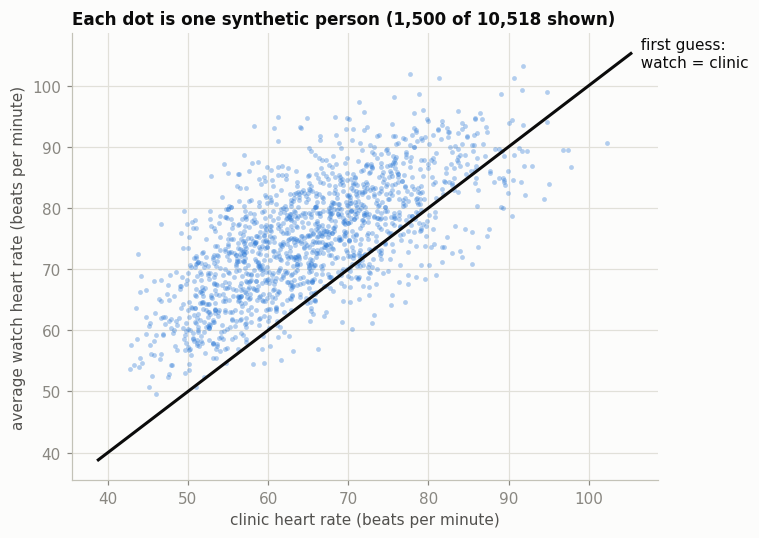

In [8]:
clinic = participants.clinic_heart_rate_bpm.to_numpy()
watch = participants.watch_heart_rate_bpm.to_numpy()

def predict(clinic_rate, slope, level):
    # The rule: start from `level` for a typical clinic rate of 65,
    # and add `slope` watch beats for every clinic beat above 65.
    return level + slope * (clinic_rate - 65)

shown = participants.sample(1500, random_state=SEED)
line = np.linspace(clinic.min(), clinic.max(), 2)
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(shown.clinic_heart_rate_bpm, shown.watch_heart_rate_bpm, s=10, alpha=0.35, color=SLOTS[0], linewidths=0)
ax.plot(line, predict(line, slope=1.0, level=65), color=INK, linewidth=2)
ax.text(line[-1], predict(line[-1], 1.0, 65), "  first guess:\n  watch = clinic", va="center", color=INK)
ax.set_xlabel("clinic heart rate (beats per minute)")
ax.set_ylabel("average watch heart rate (beats per minute)")
ax.set_title("Each dot is one synthetic person (1,500 of 10,518 shown)", loc="left")
plt.tight_layout()

### 3.1 The error function, worked by hand

For one person, the **error** is the prediction minus the truth. We square it, so that missing high and missing low
both count, and a big miss counts much more than a small one. Averaging over everyone gives the
**mean squared error**: one number for how wrong the rule is. Smaller is better; zero would be perfect.

In [9]:
def mean_squared_error(prediction, truth):
    return np.mean((prediction - truth) ** 2)

five = participants.sample(5, random_state=7)
worked = pd.DataFrame({"clinic heart rate": five.clinic_heart_rate_bpm,
                       "watch heart rate (truth)": five.watch_heart_rate_bpm})
worked["prediction (first guess)"] = predict(worked["clinic heart rate"], slope=1.0, level=65)
worked["error"] = worked["prediction (first guess)"] - worked["watch heart rate (truth)"]
worked["error squared"] = worked["error"] ** 2
display(worked.round(1))
print(f"average of these five squared errors: {worked['error squared'].mean():.1f}")
print(f"mean squared error over all {len(clinic):,} people: "
      f"{mean_squared_error(predict(clinic, slope=1.0, level=65), watch):.1f}")

,clinic heart rate,watch heart rate (truth),prediction (first guess),error,error squared
participant_id,,,,,
8109,65.4,80.6,65.4,-15.2,232.6
863,49.6,65.0,49.6,-15.4,237.8
7024,51.1,66.3,51.1,-15.2,230.1
9096,80.7,76.9,80.7,3.9,15.0
10138,63.7,83.3,63.7,-19.5,381.4


average of these five squared errors: 219.4
mean squared error over all 10,518 people: 157.4


,slope,level,mean squared error
0,1.0,65,157.4
1,0.5,70,74.1
2,0.6,75,49.2
3,1.2,85,194.6


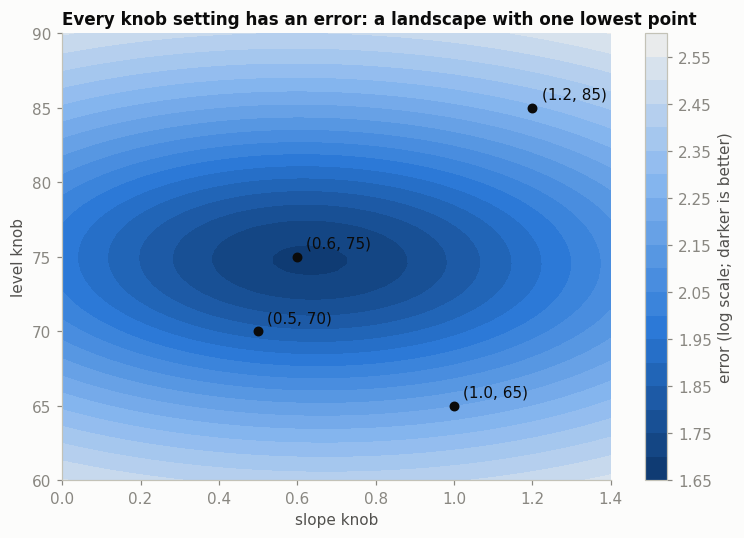

In [10]:
slopes = np.linspace(0, 1.4, 57)
levels = np.linspace(60, 90, 61)
landscape = np.array([[mean_squared_error(predict(clinic, s, l), watch) for s in slopes] for l in levels])

guesses = pd.DataFrame([(1.0, 65), (0.5, 70), (0.6, 75), (1.2, 85)], columns=["slope", "level"])
guesses["mean squared error"] = [mean_squared_error(predict(clinic, s, l), watch).round(1)
                                 for s, l in zip(guesses.slope, guesses.level)]
display(guesses)

fig, ax = plt.subplots(figsize=(7, 5))
filled = ax.contourf(slopes, levels, np.log10(landscape), levels=20, cmap=BLUES.reversed())
fig.colorbar(filled, ax=ax, label="error (log scale; darker is better)")
ax.scatter(guesses.slope, guesses.level, color=INK, s=30, zorder=3)
for s, l in zip(guesses.slope, guesses.level):
    ax.annotate(f"({s}, {l})", (s, l), textcoords="offset points", xytext=(6, 6), color=INK)
ax.set_xlabel("slope knob"); ax.set_ylabel("level knob"); ax.grid(False)
ax.set_title("Every knob setting has an error: a landscape with one lowest point", loc="left")
plt.tight_layout()

### 3.2 Learning means walking downhill

Instead of trying settings at random, the computer asks, for each knob: *if I nudge this knob up a little, does the
error go up or down, and by how much?* That direction is called the **gradient**. It then takes a small step in the
downhill direction and asks again. Repeating this is called **gradient descent**. It is how nearly every modern
model learns, including the picture model later on.

learned rule: watch = 74.7 + 0.63 x (clinic - 65)   error 49.0 (first guess 157.4)


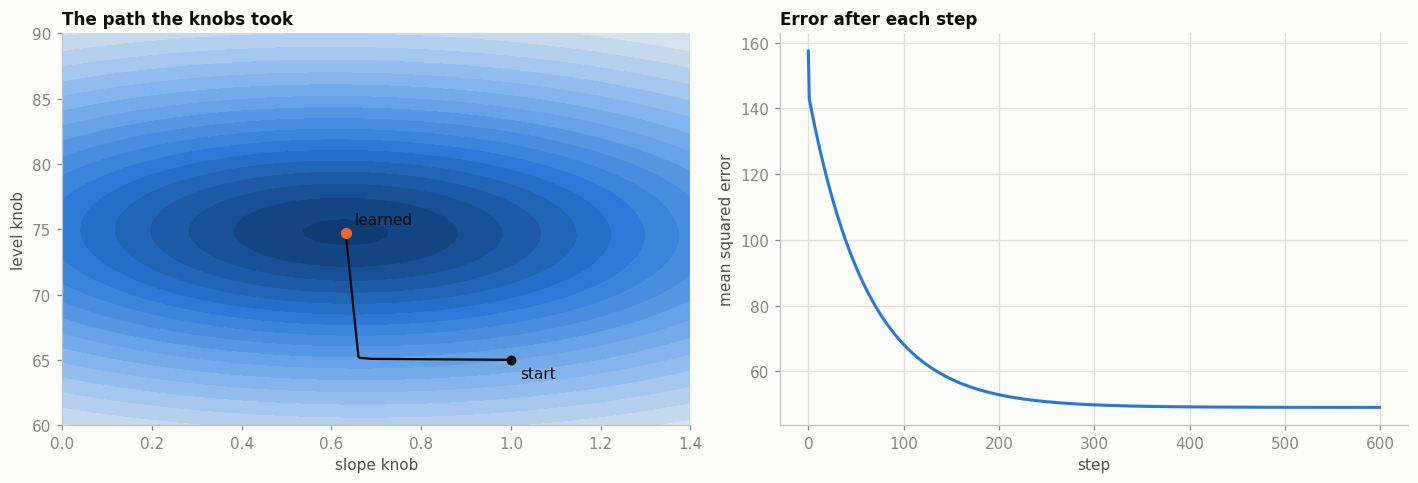

In [11]:
slope, level, step_size = 1.0, 65.0, 0.004       # start from the first guess
path = []
for step in range(600):
    error = predict(clinic, slope, level) - watch
    path.append((slope, level, np.mean(error ** 2)))
    # which way is downhill for each knob (how the mean squared error changes when the knob is nudged)
    slope_gradient = 2 * np.mean(error * (clinic - 65))
    level_gradient = 2 * np.mean(error)
    slope -= step_size * slope_gradient
    level -= step_size * level_gradient
path = np.array(path)
print(f"learned rule: watch = {level:.1f} + {slope:.2f} x (clinic - 65)   error {path[-1, 2]:.1f} "
      f"(first guess {path[0, 2]:.1f})")

fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4.5))
left.contourf(slopes, levels, np.log10(landscape), levels=20, cmap=BLUES.reversed())
left.plot(path[:, 0], path[:, 1], color=INK, linewidth=1.5)
left.scatter(*path[0, :2], color=INK, s=30, zorder=3); left.annotate("start", path[0, :2], xytext=(6, -12), textcoords="offset points")
left.scatter(*path[-1, :2], color=SLOTS[1], s=40, zorder=3); left.annotate("learned", path[-1, :2], xytext=(6, 6), textcoords="offset points")
left.set_xlabel("slope knob"); left.set_ylabel("level knob"); left.grid(False)
left.set_title("The path the knobs took", loc="left")
right.plot(path[:, 2], color=SLOTS[0])
right.set_xlabel("step"); right.set_ylabel("mean squared error")
right.set_title("Error after each step", loc="left")
plt.tight_layout()

### 3.3 When the answer is a category

In Part 5 the answer is not a number but one of four machines. The model then gives a **probability** for each
machine, adding up to 100%. The error for one example is based on the probability the model gave to the *right*
machine: confident and right is a small error, confident and wrong is a large one. The usual formula is
minus the logarithm of that probability (called *cross-entropy*):

In [12]:
probability = np.array([0.95, 0.70, 0.25, 0.05])
pd.DataFrame({
    "probability given to the right machine": probability,
    "error = -log(probability)": -np.log(probability),
    "meaning": ["confident and right", "fairly sure and right", "a blind guess among four", "confident and wrong"],
}).round(2)

,probability given to the right machine,error = -log(probability),meaning
0,0.95,0.05,confident and right
1,0.70,0.36,fairly sure and right
2,0.25,1.39,a blind guess among four
3,0.05,3.00,confident and wrong


## 4. From numbers to pictures: why a convolutional neural network

### 4.1 A picture is a grid of numbers

To a computer, a grayscale picture is a grid of numbers, one per pixel, from 0 (black) to 255 (white). Our scans
are 256 x 256 pixels, so each is 65,536 numbers.

2,000 scans of 256 x 256 pixels; 1,500 for learning, 500 held back for testing


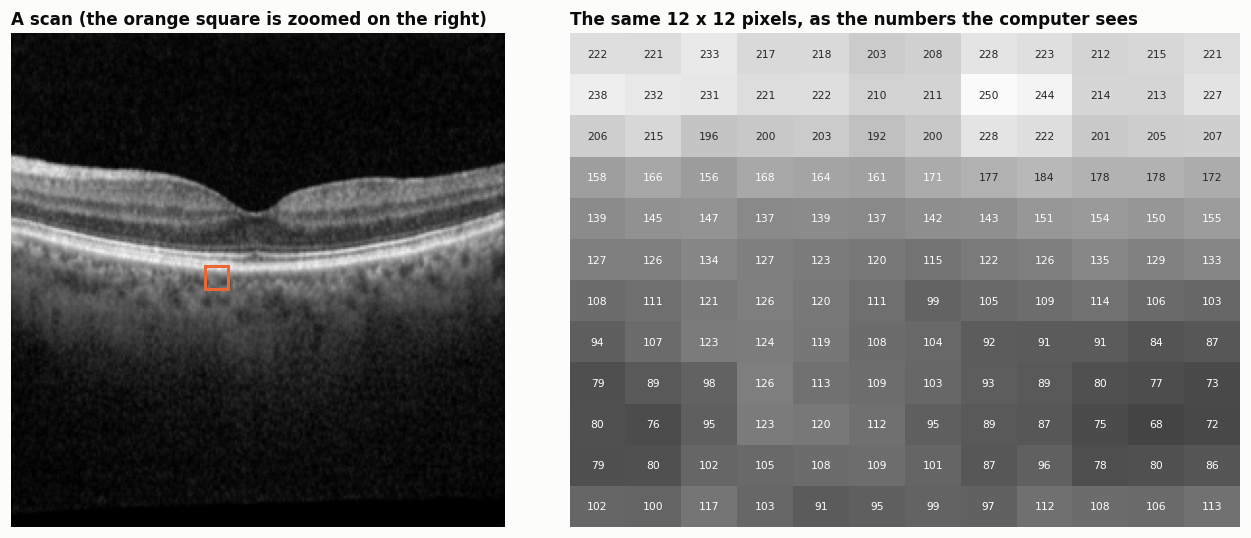

In [13]:
X = np.stack([np.array(Image.open(DATA / "scans" / name)) for name in scans.file])
labels = scans.machine.map({m: i for i, m in enumerate(MACHINES)}).to_numpy()
train_idx, test_idx = train_test_split(np.arange(len(X)), test_size=0.25, stratify=labels, random_state=SEED)
print(f"{len(X):,} scans of {X.shape[1]} x {X.shape[2]} pixels; "
      f"{len(train_idx):,} for learning, {len(test_idx):,} held back for testing")

example = X[test_idx[0]]
top, left_ = 120, 100
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1, 1.1]})
a.imshow(example, cmap="gray"); no_axes(a)
a.add_patch(plt.Rectangle((left_, top), 12, 12, fill=False, edgecolor=SLOTS[1], linewidth=2))
a.set_title("A scan (the orange square is zoomed on the right)", loc="left")
sns.heatmap(example[top:top + 12, left_:left_ + 12], annot=True, fmt="d", cmap="gray", vmin=0, vmax=255,
            cbar=False, annot_kws={"size": 7}, ax=b)
no_axes(b); b.set_title("The same 12 x 12 pixels, as the numbers the computer sees", loc="left")
plt.tight_layout()

### 4.2 Simple idea 1: compare with the average picture

Average all learning scans from each machine into one typical picture. To label a new scan, pick the machine whose
typical picture is closest to it, pixel by pixel. This works when every picture is laid out the same way, because
then each pixel position means the same thing in every scan.

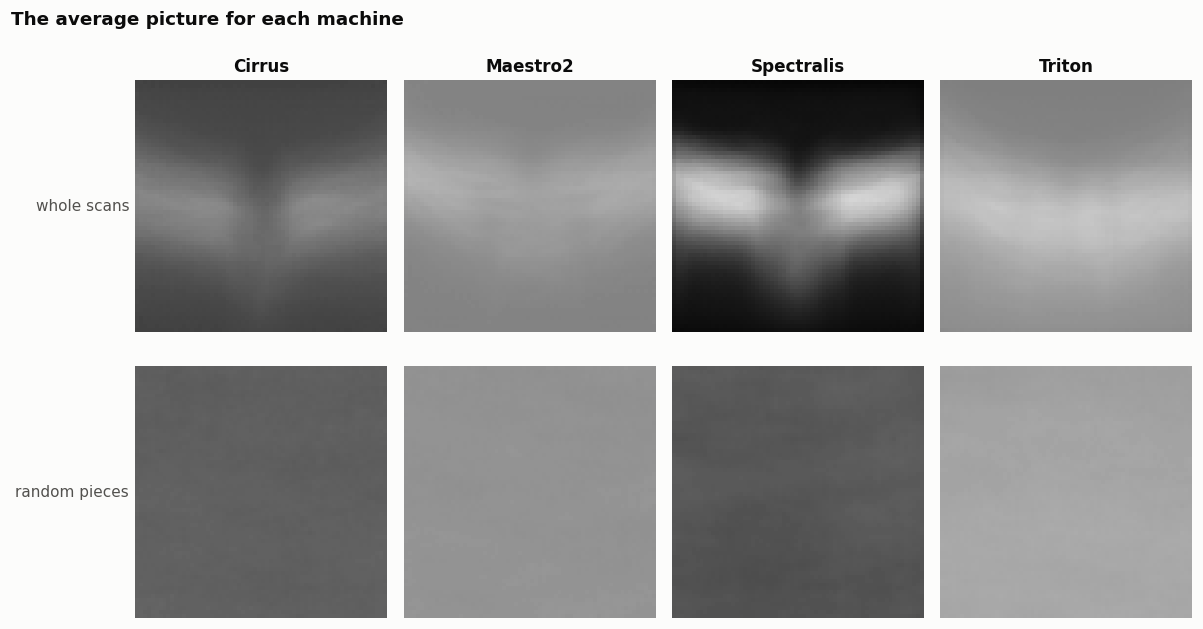

In [14]:
whole = F.avg_pool2d(torch.from_numpy(X[train_idx])[:, None].float() / 255, 4)[:, 0].numpy()   # shrink to 64 x 64
rng = np.random.default_rng(SEED)
corners = rng.integers(0, 193, size=(len(train_idx), 2))
pieces = np.stack([X[i, r:r + 64, c:c + 64] for i, (r, c) in zip(train_idx, corners)]) / 255

fig, axes = plt.subplots(2, 4, figsize=(11, 6))
for k, machine in enumerate(MACHINES):
    mine = labels[train_idx] == k
    axes[0, k].imshow(whole[mine].mean(0), cmap="gray", vmin=0, vmax=0.6)
    axes[1, k].imshow(pieces[mine].mean(0), cmap="gray", vmin=0, vmax=0.6)
    axes[0, k].set_title(machine)
    for ax in axes[:, k]:
        no_axes(ax)
axes[0, 0].set_ylabel("whole scans", rotation=0, ha="right", va="center", color=INK2)
axes[1, 0].set_ylabel("random pieces", rotation=0, ha="right", va="center", color=INK2)
fig.suptitle("The average picture for each machine", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()

### 4.3 Simple idea 2: summarize first, then decide

Describe each picture with a few summary numbers, such as how many pixels are dark, medium or bright and how much
neighboring pixels differ (how grainy it looks), then fit a simple scoring rule on those numbers. Position no
longer matters, which helps. But the arrangement of pixels, the very thing that makes up a texture, is thrown away.

### 4.4 The idea behind a convolutional neural network

A **filter** is a small grid of numbers, for example 3 x 3. Slide it across the picture. At each position, multiply
the 9 pixels under it by the 9 filter numbers and add the results. Writing each sum into a new picture gives a map
that is bright wherever the pattern in the filter appears. This sliding multiply-and-add is called a
**convolution**. Below are two filters made by hand.

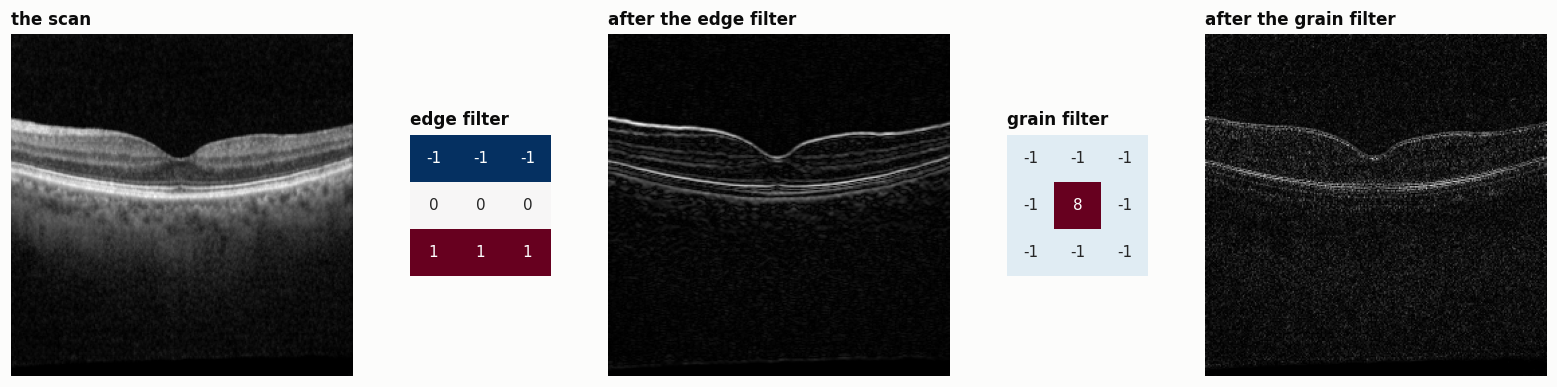

In [15]:
def convolve(picture, filt):
    # Slide a 3 x 3 filter over the picture: multiply the 9 pixels under it by the 9 filter numbers and add.
    rows, cols = picture.shape[0] - 2, picture.shape[1] - 2
    out = np.zeros((rows, cols))
    for dy in range(3):
        for dx in range(3):
            out += filt[dy, dx] * picture[dy:dy + rows, dx:dx + cols]
    return out

edge = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]])      # dark above, bright below
grain = np.array([[-1, -1, -1], [-1, 8, -1], [-1, -1, -1]])  # a pixel that differs from its neighbors

picture = X[test_idx[0]].astype(float)
fig, axes = plt.subplots(1, 5, figsize=(15, 3.6), gridspec_kw={"width_ratios": [3, 1, 3, 1, 3]})
axes[0].imshow(picture, cmap="gray"); axes[0].set_title("the scan", loc="left")
for ax, filt, name, where in [(axes[1], edge, "edge filter", axes[2]), (axes[3], grain, "grain filter", axes[4])]:
    sns.heatmap(filt, annot=True, fmt="d", cmap="RdBu_r", center=0, cbar=False, square=True, ax=ax)
    ax.set_title(name, loc="left")
    where.imshow(np.abs(convolve(picture, filt)), cmap="gray")
    where.set_title(f"after the {name}", loc="left")
for ax in axes:
    no_axes(ax)
plt.tight_layout()

### 4.5 What a convolutional neural network adds

A **convolutional neural network (CNN)** is built entirely from this idea:

* **Many filters, learned instead of hand-made.** The numbers inside every filter are knobs, tuned with the
  error-and-downhill loop from Part 3.
* **Layers.** The first layer's filters find tiny patterns such as edges and grain. The next layer slides filters
  over those results and finds combinations of patterns, and so on.
* **Shrinking.** Between layers, each 2 x 2 block keeps only its strongest value, so later layers see a wider area.
* **A final vote.** The last step turns everything into four scores, one per machine, and then probabilities.

Why a CNN fits this job better than the simple ideas:

* The same filter is used at every position, so a clue is found wherever it appears in the picture. The average
  picture needs the clue in the same place every time.
* It looks at neighboring pixels together, which is exactly what a texture is. The summary numbers throw that away.
* It needs relatively few knobs. A 3 x 3 filter has 9, whether the picture is small or large.

In [16]:
def build_cnn(n_machines=4):
    layers, channels = [], [1, 32, 64, 128]
    for c_in, c_out in zip(channels[:-1], channels[1:]):
        layers += [nn.Conv2d(c_in, c_out, kernel_size=3, padding=1),   # c_out learned 3 x 3 filters
                   nn.BatchNorm2d(c_out),                              # keeps the numbers in a steady range
                   nn.ReLU(),                                          # keeps only positive responses
                   nn.MaxPool2d(2)]                                    # shrink: keep the strongest of each 2 x 2
    return nn.Sequential(*layers, nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(channels[-1], n_machines))

cnn = build_cnn()
parts = [("filter layer 1", cnn[0:2], "32 filters looking at the picture"),
         ("filter layer 2", cnn[4:6], "64 filters looking at layer 1's maps"),
         ("filter layer 3", cnn[8:10], "128 filters looking at layer 2's maps"),
         ("final vote", cnn[-1], "turns 128 summaries into 4 machine scores")]
knobs = pd.DataFrame([{"step": name, "what it does": what, "knobs": sum(p.numel() for p in part.parameters())}
                      for name, part, what in parts]).set_index("step")
print(f"total knobs: {knobs.knobs.sum():,}")
knobs

total knobs: 93,636


,what it does,knobs
step,,
filter layer 1,32 filters looking at the picture,384
filter layer 2,64 filters looking at layer 1's maps,18624
filter layer 3,128 filters looking at layer 2's maps,74112
final vote,turns 128 summaries into 4 machine scores,516


## 5. The challenge: which machine took this scan?

Every imaging machine leaves a fingerprint: its optics, its sensor, its processing. Fingerprints matter because a
model trained to spot disease can quietly learn to spot the *machine* instead, for example when one clinic with
sicker patients uses one machine. In a well-known study, a model could tell which *hospital* a chest X-ray came
from almost perfectly ([Zech et al., 2018](https://doi.org/10.1371/journal.pmed.1002683)).

Last year's AI-READI demo showed that a model can name the machine from small grayscale pieces of retina pictures
that people cannot tell apart. We repeat it on synthetic scans, which adds one more question: **did the program that
generated the data also reproduce each machine's fingerprint?**

We make the task harder step by step. With four machines, guessing gets 25% right.

| Level | What the model sees |
|---|---|
| 1. Whole scan | the full scan, shrunk to 64 x 64 pixels |
| 2. Random piece | a random 64 x 64 piece at full detail |
| 3. Piece, brightness evened out | the same, with overall brightness and contrast made identical |
| 4. Pure texture | a piece with no visible shapes at all: no layer edges, streaks or dark bands |

### 5.1 Finding pieces with no visible shapes

To build level 4 we need a way to say "this piece shows something a person could spot". Two simple checks:

1. **Brightness changes.** Average each row, each column and each 8 x 8 block, and see how much those averages
   vary compared with the pixel-to-pixel grain. On pure grain they barely move (a score of about 0.15 to 0.25); a
   layer edge, a streak or a dark band makes them swing (0.5 or more). We keep pieces below 0.3.
2. **Grain changes.** Compare the roughest row, column or 8 x 8 block with the smoothest one. In even grain the
   roughest is less than about twice the smoothest; a flat band along an edge or a bright speck in a corner pushes
   that far higher. We keep pieces below 2.5.

We also skip nearly blank pieces such as pure black background, since a blank square would itself be a giveaway.

Each piece also starts at a slightly random position. The program that generated these synthetic images leaves a
faint pattern that repeats every 8 pixels; if every piece started on the same grid, that pattern would line up and
even the average picture could use it. Random starts close that shortcut.

scored 288,000 pieces in 23 s
scans with at least one shapeless piece: {'Cirrus': '100%', 'Maestro2': '75%', 'Spectralis': '33%', 'Triton': '33%'}


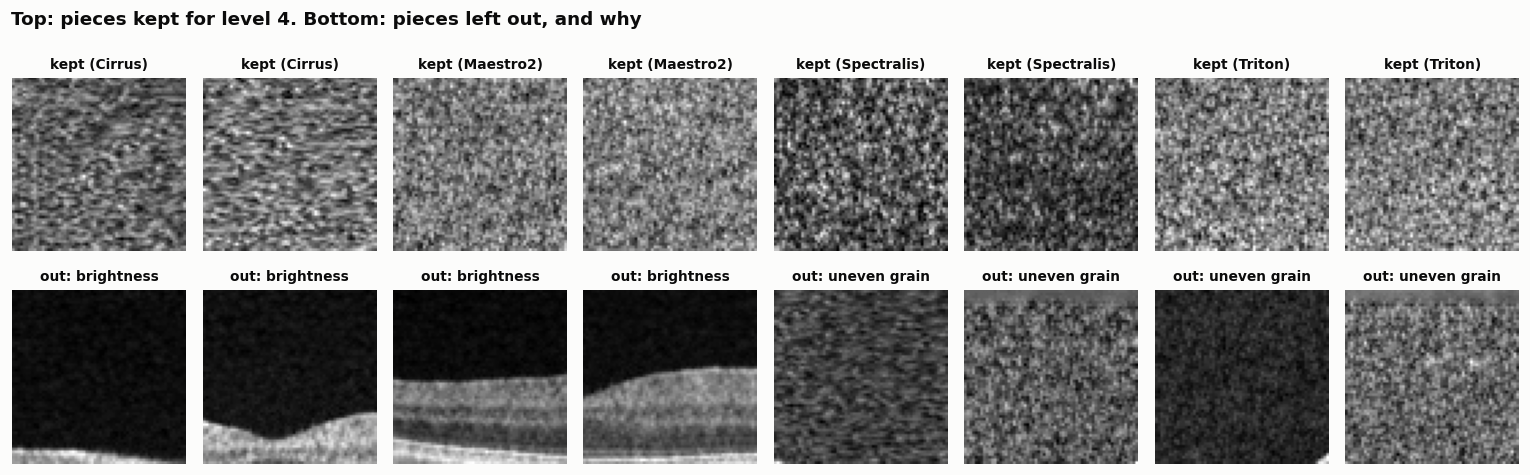

In [17]:
GRID = [(r, c) for r in range(0, 185, 16) for c in range(0, 185, 16)]   # 144 piece positions per scan

def shape_score(pieces):
    # How much brightness swings across rows, columns and 8 x 8 blocks, relative to the pixel-to-pixel grain.
    z = (pieces - pieces.mean((1, 2), keepdims=True)) / (pieces.std((1, 2), keepdims=True) + 1e-6)
    rows = z.mean(2).std(1)
    columns = z.mean(1).std(1)
    blocks = z.reshape(-1, 8, 8, 8, 8).mean((2, 4)).std((1, 2))
    return np.maximum(np.maximum(rows, columns), blocks)

def unevenness(pieces):
    # The roughest row, column or 8 x 8 block divided by the smoothest one. Even grain: about 1.5 to 2.
    def spread(roughness):
        return roughness.max(1) / (roughness.min(1) + 1e-6)
    blocks = pieces.reshape(-1, 8, 8, 8, 8).std((2, 4)).reshape(len(pieces), -1)
    return np.maximum(np.maximum(spread(pieces.std(2)), spread(pieces.std(1))), spread(blocks))

t0 = time.time()
rng = np.random.default_rng(SEED)
plain_spots, examples = [], []
for i in range(len(X)):
    scan = X[i].astype(np.float32)
    corners = [(r + rng.integers(0, 8), c + rng.integers(0, 8)) for r, c in GRID]   # random start, 0 to 7 pixels
    pieces = np.stack([scan[r:r + 64, c:c + 64] for r, c in corners])
    shape, uneven = shape_score(pieces), unevenness(pieces)
    keep = (shape < 0.3) & (uneven < 2.5) & (pieces.std((1, 2)) >= 4)
    plain_spots.append([corner for corner, k in zip(corners, keep) if k])
    if i < 300:
        examples += [(pieces[j], labels[i], shape[j], uneven[j]) for j in range(0, len(corners), 7)]
has_plain = np.array([len(s) > 0 for s in plain_spots])
print(f"scored {len(X) * len(GRID):,} pieces in {time.time() - t0:.0f} s")
print("scans with at least one shapeless piece:",
      {m: f"{has_plain[labels == k].mean():.0%}" for k, m in enumerate(MACHINES)})

usable = [e for e in examples if e[0].std() >= 4]
kept = [e for k in range(len(MACHINES)) for e in [x for x in usable if x[1] == k and x[2] < 0.3 and x[3] < 2.5][:2]]
edges = [e for e in usable if e[2] >= 0.3][:4]
bands = [e for e in usable if e[2] < 0.3 and e[3] >= 2.5][:4]
fig, axes = plt.subplots(2, 8, figsize=(14, 4.6))
for ax, (piece, k, shape, uneven) in zip(axes[0], kept):
    ax.imshow((piece - piece.mean()) / (piece.std() + 1e-6), cmap="gray"); no_axes(ax)
    ax.set_title(f"kept ({MACHINES[k]})", fontsize=9)
for ax, (piece, k, shape, uneven), reason in zip(axes[1], edges + bands, ["brightness"] * 4 + ["uneven grain"] * 4):
    ax.imshow((piece - piece.mean()) / (piece.std() + 1e-6), cmap="gray"); no_axes(ax)
    ax.set_title(f"out: {reason}", fontsize=9)
fig.suptitle("Top: pieces kept for level 4. Bottom: pieces left out, and why",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()

level 4 uses 119 learning and 40 test scans per machine


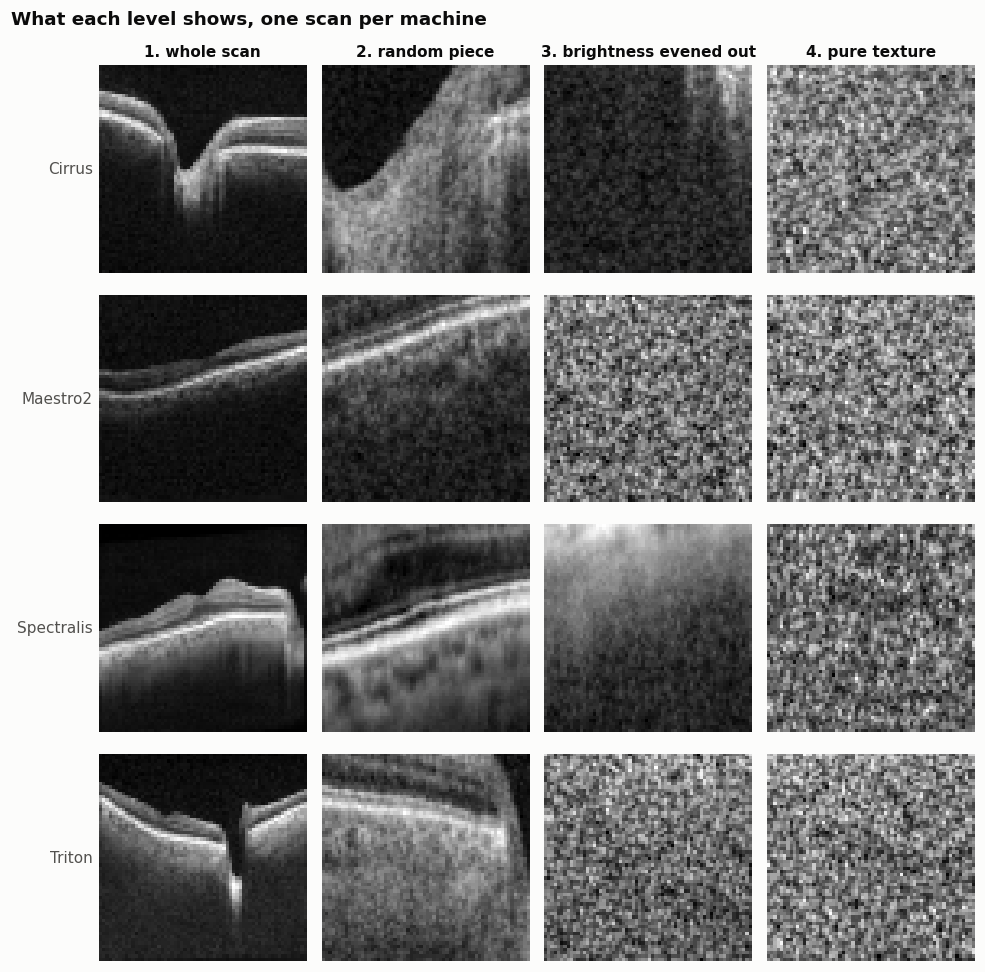

In [18]:
LEVELS = {"whole": "1. whole scan", "piece": "2. random piece",
          "even": "3. brightness evened out", "texture": "4. pure texture"}
Xt = torch.from_numpy(X)

def make_view(idx, level, seed):
    # What the model gets to see at each level, for the scans in idx.
    rng = np.random.default_rng(seed)
    batch = Xt[idx]
    if level == "whole":
        return torch.cat([F.avg_pool2d(b[:, None].float() / 255, 4) for b in batch.split(500)])
    if level == "texture":
        corners = [plain_spots[i][rng.integers(len(plain_spots[i]))] for i in idx]
    else:
        corners = rng.integers(0, 193, size=(len(idx), 2))
    pieces = torch.stack([im[r:r + 64, c:c + 64] for im, (r, c) in zip(batch, corners)])[:, None].float() / 255
    if level in ("even", "texture"):
        pieces = (pieces - pieces.mean((2, 3), keepdim=True)) / (pieces.std((2, 3), keepdim=True) + 1e-6)
    return pieces

def balanced(idx):
    # scans that have a shapeless piece, with the same number from each machine
    idx = idx[has_plain[idx]]
    n = min((labels[idx] == k).sum() for k in range(len(MACHINES)))
    rng = np.random.default_rng(SEED)
    return np.concatenate([rng.choice(idx[labels[idx] == k], n, replace=False) for k in range(len(MACHINES))])

texture_train, texture_test = balanced(train_idx), balanced(test_idx)
print(f"level 4 uses {len(texture_train) // 4} learning and {len(texture_test) // 4} test scans per machine")

fig, axes = plt.subplots(len(MACHINES), len(LEVELS), figsize=(9, 9))
for k, machine in enumerate(MACHINES):
    scan = int(texture_train[labels[texture_train] == k][0])
    for j, level in enumerate(LEVELS):
        ax = axes[k, j]
        ax.imshow(make_view([scan], level, seed=j)[0, 0], cmap="gray"); no_axes(ax)
        if k == 0: ax.set_title(LEVELS[level], fontsize=10)
        if j == 0: ax.set_ylabel(machine, rotation=0, ha="right", va="center", color=INK2)
fig.suptitle("What each level shows, one scan per machine", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()

### 5.2 Your turn

Below are 12 pure-texture pieces (level 4) from scans held back for testing. Study the labeled examples in the top
row, then write down a letter for each numbered piece.

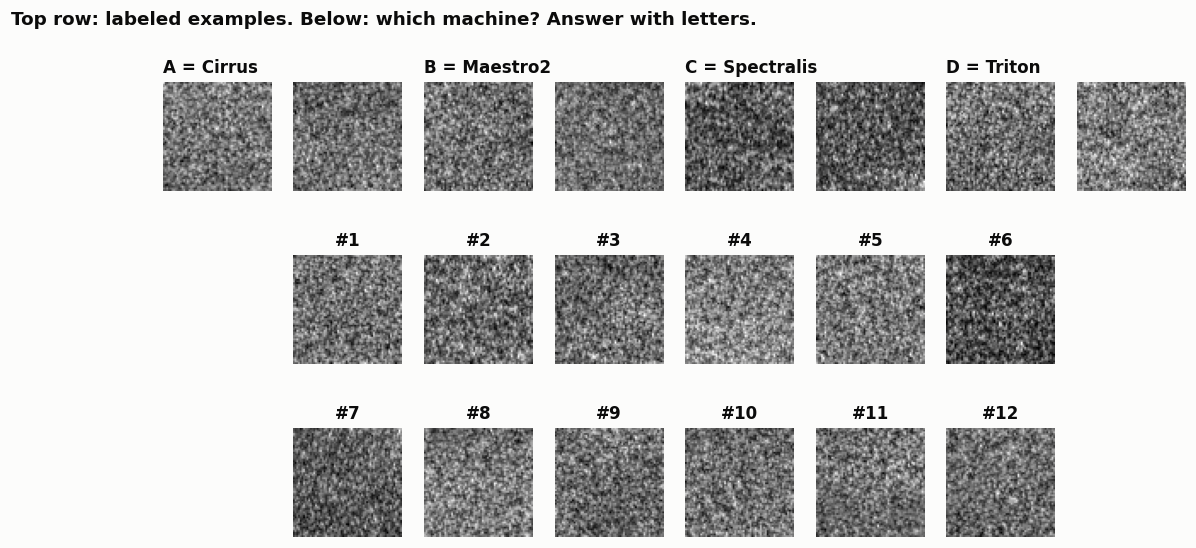

In [19]:
LETTERS = {m: chr(65 + k) for k, m in enumerate(MACHINES)}
rng = np.random.default_rng(2026)
quiz_scans = rng.permutation(np.concatenate(
    [rng.choice(texture_test[labels[texture_test] == k], 3, replace=False) for k in range(len(MACHINES))]))
quiz_views = make_view(quiz_scans, "texture", seed=2026)

fig = plt.figure(figsize=(12, 5.6))
grid = fig.add_gridspec(3, 8, hspace=0.35)
for k, machine in enumerate(MACHINES):                    # labeled study examples: two per machine
    for s in range(2):
        ax = fig.add_subplot(grid[0, 2 * k + s])
        scan = int(texture_train[labels[texture_train] == k][5 + s])
        ax.imshow(make_view([scan], "texture", seed=s)[0, 0], cmap="gray"); no_axes(ax)
        if s == 0: ax.set_title(f"{LETTERS[machine]} = {machine}", loc="left")
for q in range(12):                                      # the quiz
    ax = fig.add_subplot(grid[1 + q // 6, (q % 6) + 1])
    ax.imshow(quiz_views[q, 0], cmap="gray"); no_axes(ax)
    ax.set_title(f"#{q + 1}")
fig.suptitle("Top row: labeled examples. Below: which machine? Answer with letters.",
             x=0.01, ha="left", fontweight="bold")
plt.show()

In [20]:
MY_GUESSES = ""   # for example "ABDCCABDAACB", one letter per numbered piece
print(f"{len(MY_GUESSES.strip())} of 12 answers entered")

0 of 12 answers entered


### 5.3 The simple ideas against the CNN

For each level we now run all three approaches on the same learning scans and test them on the same held-back scans:

* **Average picture** (idea 1): closest typical picture, pixel by pixel.
* **Summary numbers** (idea 2): 24 brightness counts plus two graininess numbers, then a simple scoring rule.
* **CNN**: learns its filters with the error-and-downhill loop, 8 passes over the learning scans.

At level 4 each scan contributes 6 different shapeless pieces, to give every approach more texture to learn from.
On a 4-core laptop this cell takes a few minutes.

In [21]:
EPOCHS = 8

def average_picture_rule(train_views, train_answers, test_views):
    flat_train, flat_test = train_views.flatten(1).numpy(), test_views.flatten(1).numpy()
    averages = np.stack([flat_train[train_answers == k].mean(0) for k in range(len(MACHINES))])
    distances = ((flat_test[:, None, :] - averages[None]) ** 2).sum(2)
    return distances.argmin(1)

def summary_numbers(views, level):
    v = views[:, 0].numpy()
    low, high = (-3, 3) if level in ("even", "texture") else (0, 1)
    counts = np.stack([np.histogram(p, bins=24, range=(low, high))[0] for p in v]) / v[0].size
    grain_across = np.abs(np.diff(v, axis=2)).mean((1, 2))
    grain_down = np.abs(np.diff(v, axis=1)).mean((1, 2))
    return np.column_stack([counts, grain_across, grain_down])

def train_cnn(level, train_scans, pieces_per_scan):
    torch.manual_seed(SEED)
    model = build_cnn()
    n = len(train_scans) * pieces_per_scan
    optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-4)   # a refined downhill step
    schedule = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=4e-3, total_steps=EPOCHS * ((n + 127) // 128))
    answers = torch.from_numpy(np.tile(labels[train_scans], pieces_per_scan))
    for epoch in range(EPOCHS):
        model.train()
        views = torch.cat([make_view(train_scans, level, seed=100 * epoch + k) for k in range(pieces_per_scan)])
        for batch in torch.randperm(n).split(128):
            if len(batch) < 2:
                continue
            error = F.cross_entropy(model(views[batch]), answers[batch])   # the error function from 3.3
            optimizer.zero_grad()
            error.backward()                                                # which way is downhill, for every knob
            optimizer.step(); schedule.step()                               # take the step
    return model.eval()

@torch.no_grad()
def cnn_predict(model, views):
    return torch.cat([model(v).argmax(1) for v in views.split(512)]).numpy()

results, cnns = [], {}
for level, name in LEVELS.items():
    t0 = time.time()
    learn, test = (texture_train, texture_test) if level == "texture" else (train_idx, test_idx)
    per_scan = 6 if level == "texture" else 1
    learn_views = torch.cat([make_view(learn, level, seed=k) for k in range(per_scan)])
    learn_answers = np.tile(labels[learn], per_scan)
    test_views = make_view(test, level, seed=999)
    truth = labels[test]
    average = (average_picture_rule(learn_views, learn_answers, test_views) == truth).mean()
    rule = LogisticRegression(max_iter=2000).fit(summary_numbers(learn_views, level), learn_answers)
    summary = (rule.predict(summary_numbers(test_views, level)) == truth).mean()
    cnns[level] = train_cnn(level, learn, per_scan)
    cnn_right = (cnn_predict(cnns[level], test_views) == truth).mean()
    results.append({"level": name, "average picture": average, "summary numbers": summary, "CNN": cnn_right})
    print(f"{name:26s} average picture {average:5.1%}   summary numbers {summary:5.1%}   CNN {cnn_right:5.1%}"
          f"   ({time.time() - t0:.0f} s)")
results = pd.DataFrame(results).set_index("level")

1. whole scan              average picture 91.8%   summary numbers 91.6%   CNN 99.2%   (54 s)


2. random piece            average picture 49.4%   summary numbers 77.0%   CNN 89.0%   (54 s)


3. brightness evened out   average picture 26.6%   summary numbers 43.0%   CNN 79.6%   (53 s)


4. pure texture            average picture 38.8%   summary numbers 73.1%   CNN 86.9%   (101 s)


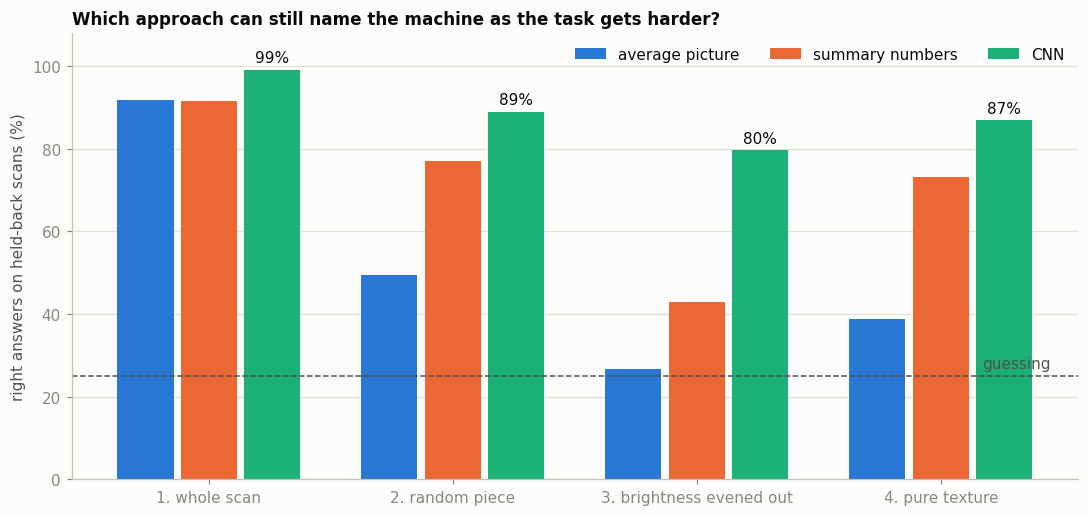

In [22]:
methods = ["average picture", "summary numbers", "CNN"]
x = np.arange(len(results))
width = 0.26
fig, ax = plt.subplots(figsize=(10, 4.8))
for k, method in enumerate(methods):
    bars = ax.bar(x + (k - 1) * width, results[method] * 100, width=width - 0.03, color=SLOTS[k], label=method)
    if method == "CNN":
        ax.bar_label(bars, labels=[f"{v:.0%}" for v in results[method]], padding=3, color=INK)
ax.axhline(25, color=INK2, linestyle="--", linewidth=1)
ax.text(x[-1] + 0.45, 27, "guessing", ha="right", color=INK2)
ax.set_xticks(x, results.index)
ax.set_ylim(0, 108); ax.set_ylabel("right answers on held-back scans (%)"); ax.grid(axis="x", visible=False)
ax.legend(loc="upper right", frameon=False, ncols=3)
ax.set_title("Which approach can still name the machine as the task gets harder?", loc="left")
plt.tight_layout()

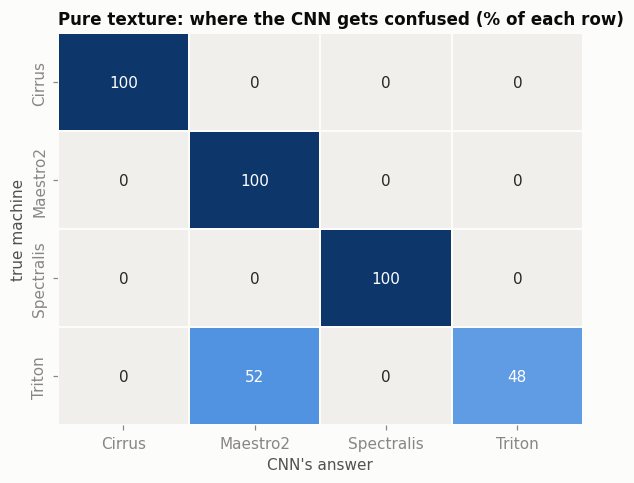

In [23]:
level = "texture"
truth = labels[texture_test]
guess = cnn_predict(cnns[level], make_view(texture_test, level, seed=999))
table = pd.crosstab(pd.Series([MACHINES[k] for k in truth], name="true machine"),
                    pd.Series([MACHINES[k] for k in guess], name="CNN's answer"), normalize="index") * 100
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(table, annot=True, fmt=".0f", cmap=BLUES, cbar=False, linewidths=1, linecolor=SURFACE, ax=ax)
ax.grid(False)
ax.set_title("Pure texture: where the CNN gets confused (% of each row)", loc="left")
plt.tight_layout()

### 5.4 The reveal

In [24]:
quiz_guess = cnn_predict(cnns["texture"], quiz_views)
answer = pd.DataFrame({
    "piece": [f"#{q + 1}" for q in range(12)],
    "right answer": [f"{LETTERS[MACHINES[k]]} {MACHINES[k]}" for k in labels[quiz_scans]],
    "CNN": [f"{LETTERS[MACHINES[k]]} {MACHINES[k]}" for k in quiz_guess],
}).set_index("piece")
answer["you"] = list(MY_GUESSES.strip().upper().ljust(12, "-"))[:12]
cnn_score = (quiz_guess == labels[quiz_scans]).sum()
your_score = sum(g == r[0] for g, r in zip(answer["you"], answer["right answer"]))
print(f"CNN: {cnn_score}/12   you: {your_score}/12   guessing: about 3/12")
answer

CNN: 12/12   you: 0/12   guessing: about 3/12


,right answer,CNN,you
piece,,,
#1,B Maestro2,B Maestro2,-
#2,C Spectralis,C Spectralis,-
#3,D Triton,D Triton,-
#4,D Triton,D Triton,-
#5,B Maestro2,B Maestro2,-
#6,C Spectralis,C Spectralis,-
#7,C Spectralis,C Spectralis,-
#8,A Cirrus,A Cirrus,-
#9,B Maestro2,B Maestro2,-


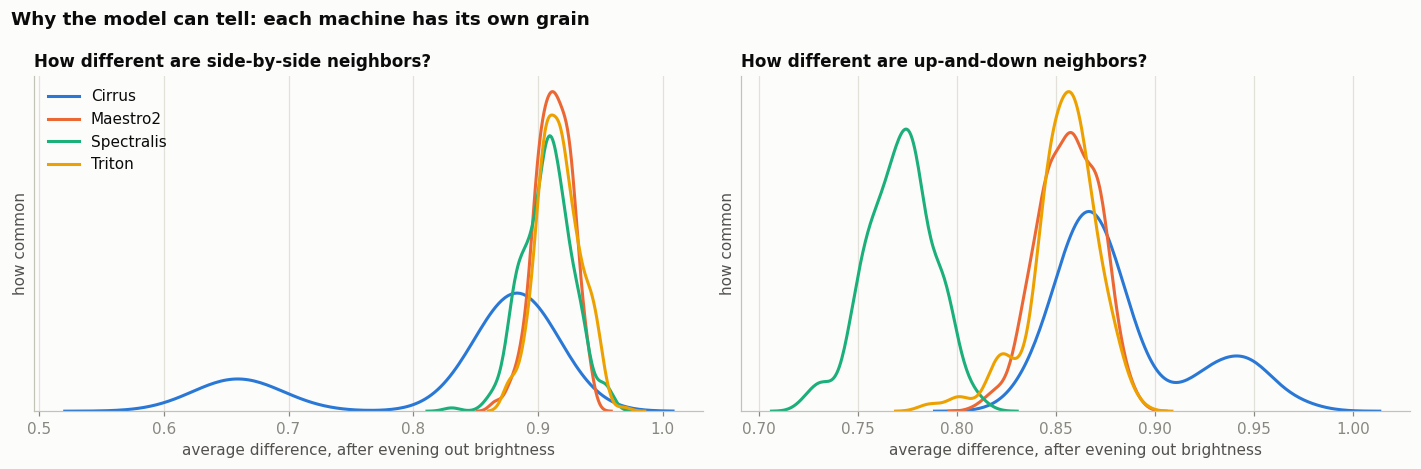

In [25]:
views = torch.cat([make_view(texture_test, "texture", seed=999 + k) for k in range(6)])[:, 0].numpy()
owner = np.tile(labels[texture_test], 6)
side_by_side = np.abs(np.diff(views, axis=2)).mean((1, 2))   # each pixel against its right-hand neighbor
up_and_down = np.abs(np.diff(views, axis=1)).mean((1, 2))    # each pixel against the one below it

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for ax, values, title in [(axes[0], side_by_side, "side-by-side neighbors"), (axes[1], up_and_down, "up-and-down neighbors")]:
    for k, machine in enumerate(MACHINES):
        sns.kdeplot(values[owner == k], ax=ax, color=SLOTS[k], label=machine, linewidth=2)
    ax.set_title(f"How different are {title}?", loc="left")
    ax.set_xlabel("average difference, after evening out brightness"); ax.set_ylabel("how common"); ax.set_yticks([])
axes[0].legend(frameon=False, loc="upper left")
fig.suptitle("Why the model can tell: each machine has its own grain", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()

## 6. What it means

* **Machines leave fingerprints, even in pure static.** A model meant to detect disease can learn the machine
  instead. Any medical image model should be tested on machines and clinics it did not learn from.
* **The synthetic data reproduced those fingerprints**, which makes it useful for building and testing methods
  before applying for the real data.
* **Use the simplest tool that works.** When pictures are laid out the same way, simple rules do well. A CNN earns
  its place when the clue is a texture or pattern that can appear anywhere.

**Questions worth a grant**

1. *Machine-independent eye measurements.* Teach models to see disease but not the machine, and use this notebook's
   machine test as the check. AI-READI images the same people on several machines, which makes this testable.
2. *The eye as a window on whole-body health.* In the real data, pictures and lab results belong to the same people:
   can the retina show blood sugar control, kidney health or who is moving toward health?
3. *Glucose in daily life.* Relate glucose monitor patterns to sleep, stress, activity and the home environment.
4. *How faithful is synthetic data?* Part 2 found that strong relationships survived and some weaker ones did not.
   A systematic way to measure that would help every synthetic health dataset.

## 7. Data license and credits

The sample in `data/` is covered by the **AI-READI Synthetic Data License Agreement** (Licensor: Washington University
in St. Louis); the full text is in `data/LICENSE-AI-READI-synthetic-data.pdf`. In short: use it only if the license
covers you, do not post or share it as a standalone download, and never try to identify the real people behind the
source data. Figures from this notebook can appear in presentations and papers with the acknowledgement below.

**Acknowledgement.** Synthetic data: Jackson N, Espinosa Dice N, Yan C, Li Z, Jiang X, Lee A, Malin B. *Synthetic
AI-READI Dataset for T2DM Research*, ADVANCE Center, Vanderbilt University Medical Center, 2026,
[doi:10.5281/zenodo.22944362](https://doi.org/10.5281/zenodo.22944362). Source study: AI-READI Consortium,
*Nature Metabolism* 2024, [doi:10.1038/s42255-024-01165-x](https://doi.org/10.1038/s42255-024-01165-x), and AI-READI
dataset v3.0.0, [doi:10.60775/fairhub.3](https://doi.org/10.60775/fairhub.3). Funding: NIH Bridge2AI OT2OD032644,
National Library of Medicine K99LM014428 and T15LM007450, National Human Genome Research Institute U54HG012510.
Licensor: Washington University in St. Louis.

**Further reading.** AI-READI documentation: [docs.aireadi.org](https://docs.aireadi.org/). Machine fingerprints in
medical images: Zech et al., *PLOS Medicine* 2018, [doi:10.1371/journal.pmed.1002683](https://doi.org/10.1371/journal.pmed.1002683).